In [1]:
import pandas as pd
import numpy as np
import sys
import os 
from scipy.stats import kurtosis


sys.path.append(os.path.abspath(".."))
from src.build_dataset import build_dataset

In [16]:
def _returns(df: pd.DataFrame, indicator: str, close_col: str) -> pd.DataFrame:
    df_ = df.copy()
    df_["prev_close"] = df_.groupby(indicator)[close_col].shift(1)
    df_ = df_[~(df_["prev_close"].isna())]
    return df_


def _log_return(df: pd.DataFrame, close: str, prev_close: str) -> pd.Series:
    return np.log(df[close] / df[prev_close])


def _simple_return(df: pd.DataFrame, close: str, prev_close: str) -> pd.Series:
    return (df[close] / df[prev_close]) - 1


def diff(df: pd.DataFrame, log_return_col: str, simple_return_col: str)-> pd.Series:
    return df[simple_return_col] - df[log_return_col]


def calculate_logreturns_and_simplereturns(indicator: str, close: str, prev_close: str) -> pd.DataFrame:
    """ Calculating log returns and simple returns for companies in stock_df. """
    
    df = build_dataset()
    df = df[0]
    df_ = df.copy()
    df_ = _returns(df_, indicator, close)
    df_["log_ret"] = _log_return(df_, close, prev_close)
    df_["simple_ret"] = _simple_return(df_, close, prev_close)
    df_["diff"] = diff(df_, "log_ret", "simple_ret")
    
    return df_


def find_biggest_diff(df: pd.DataFrame, indicator: str, diff_col: str, date_col: str) -> pd.DataFrame:
    """ Calculating biggest difference between log return and simple return. """
    
    indx = df.groupby(indicator)[diff_col].idxmax()
    return df.loc[indx, [indicator, date_col, diff_col]]


def moments(df: pd.DataFrame, indicator: str, log_return_col) -> pd.DataFrame:
    """ Calculating mean, standard deviaton (daily and yearly), skewness, kurtosis for each ticker in stock_df. """
    
    return df.groupby(indicator).agg(
        avg_daily_log_ret = (log_return_col, "mean"),
        std_daily = (log_return_col, "std"),
        std_yearly = (log_return_col, lambda x:x.std() * np.sqrt(252)),
        skew = (log_return_col, "skew"),
        excess_kurtosis = (log_return_col, lambda x: x.kurt())
    )
    

def comp_moments_and_vals_from_normal_distr(df: pd.DataFrame, seed: int, number_counts: int) -> pd.DataFrame:
    """ Calculating moments for values from normal distibuation". Condition: mean=0, because it is nearly 0 based on data from moments function. """
    
    skew_norm = []
    excess_kurtosis_norm = []
    
    for ind in df.index:
        rng = np.random.default_rng(seed)
        mean = 0
        std = df.loc[ind,"std_daily"]
        vals = pd.Series(rng.normal(mean,std,number_counts))
        skew_norm.append(vals.skew())
        excess_kurtosis_norm.append(vals.kurt())
    
    df["skewness_normal_distribution"] = skew_norm
    df["excess_kurtosis_normal_distribution"] = excess_kurtosis_norm
    
    return df


def price_simulation(df: pd.DataFrame, chosen_bank: str, seed: int, number_counts: int) -> pd.Series:
    
    chosenbank_mean = df.loc[chosen_bank, "avg_daily_log_ret"]
    chosenbank_std = df.loc[chosen_bank, "std_daily"]
    rng = np.random.default_rng(seed)
    vals = pd.Series(
        rng.normal(250 * chosenbank_mean, np.sqrt(250) * chosenbank_std, number_counts)
    )
    prices = 100 * np.e ** vals
    return prices

In [8]:
stocks_df = calculate_logreturns_and_simplereturns("ticker", "adjclose", "prev_close")
stocks_df.head(3)

,date,ticker,currency,open,high,low,close,adjclose,volume,prev_close,log_ret,simple_ret,diff
1,2015-01-02,Alior,PLN,63.563641,63.628902,62.470531,62.853935,50.757290,83972,51.369934,-0.011998,-0.011926,0.000072
2,2015-01-05,Alior,PLN,62.617367,65.097260,61.532413,61.532413,49.690102,90079,50.757290,-0.021249,-0.021025,0.000224
3,2015-01-07,Alior,PLN,61.695564,64.852531,61.695564,62.242119,50.263218,155186,49.690102,0.011468,0.011534,0.000066


In [9]:
find_biggest_diff(stocks_df, "ticker", "diff", "date")

,ticker,date,diff
1294,Alior,2020-03-12,0.022844
4855,ING,2022-07-29,0.008037
7220,Millennium,2020-03-12,0.026713
10674,PKO BP,2022-02-24,0.015965
13146,Pekao,2020-03-12,0.022133
16251,mBank,2020-11-09,0.025064


In [10]:
moments_df = moments(stocks_df, "ticker", "log_ret")
moments_df

,avg_daily_log_ret,std_daily,std_yearly,skew,excess_kurtosis
ticker,,,,,
Alior,0.000333,0.025501,0.404808,-0.280943,6.807779
ING,0.000539,0.019620,0.311461,0.137360,3.954093
Millennium,0.000340,0.026660,0.423213,-0.347812,6.903975
PKO BP,0.000514,0.020393,0.323730,-0.316262,5.613795
Pekao,0.000382,0.020659,0.327954,-0.488095,9.469412
mBank,0.000422,0.025473,0.404363,0.256878,5.363129


In [14]:
moments_normal_distr = comp_moments_and_vals_from_normal_distr(moments_df,42,100_00)
moments_normal_distr

,avg_daily_log_ret,std_daily,std_yearly,skew,excess_kurtosis,skewness_normal_distribution,excess_kurtosis_normal_distribution
ticker,,,,,,,
Alior,0.000333,0.025501,0.404808,-0.280943,6.807779,-0.003358,0.0533
ING,0.000539,0.019620,0.311461,0.137360,3.954093,-0.003358,0.0533
Millennium,0.000340,0.026660,0.423213,-0.347812,6.903975,-0.003358,0.0533
PKO BP,0.000514,0.020393,0.323730,-0.316262,5.613795,-0.003358,0.0533
Pekao,0.000382,0.020659,0.327954,-0.488095,9.469412,-0.003358,0.0533
mBank,0.000422,0.025473,0.404363,0.256878,5.363129,-0.003358,0.0533


In [20]:
prices = price_simulation(moments_normal_distr, "PKO BP", 42, 100_000)
prices_mean = prices.mean()
prices_median = prices.median()

<Axes: >

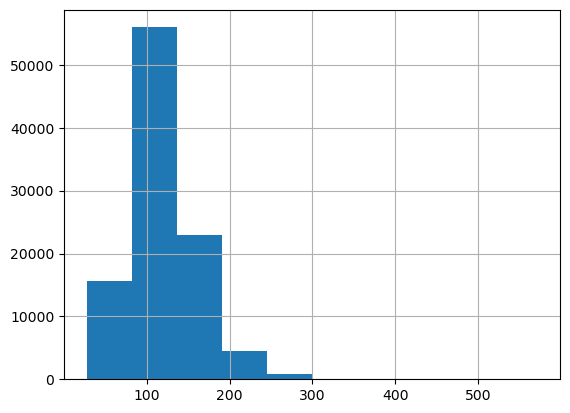

In [22]:
prices.hist()

In [24]:
prices_mean

119.67175749703452

In [26]:
prices_median

113.385645539269